In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

IMAGE_PATH = "frame_0216.png"

# OpenCV HSV ranges: H 0-179, S 0-255, V 0-255
HUE_MIN, HUE_MAX = 0, 40   # red -> orange -> yellow
SAT_MIN = 130              # drop pale regions like smoke and clouds
VAL_MIN = 150              # keep only bright pixels
OPEN_KERNEL = 3            # noise removal
DILATE_KERNEL = 5          # merge nearby flame pieces

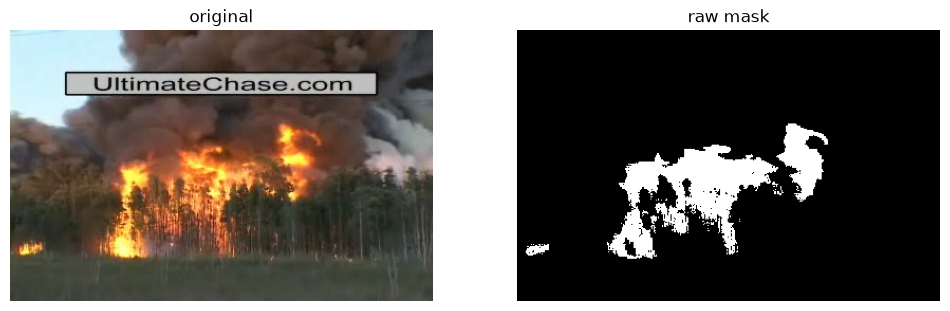

In [2]:
# threshold in HSV
image = cv2.imread(IMAGE_PATH)
hue, sat, val = cv2.split(cv2.cvtColor(image, cv2.COLOR_BGR2HSV))

raw_mask = (hue >= HUE_MIN) & (hue <= HUE_MAX) & (sat >= SAT_MIN) & (val >= VAL_MIN)
raw_mask = raw_mask.astype(np.uint8) * 255

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB)); axes[0].set_title("original")
axes[1].imshow(raw_mask, cmap="gray"); axes[1].set_title("raw mask")
for ax in axes: ax.axis("off")
plt.show()

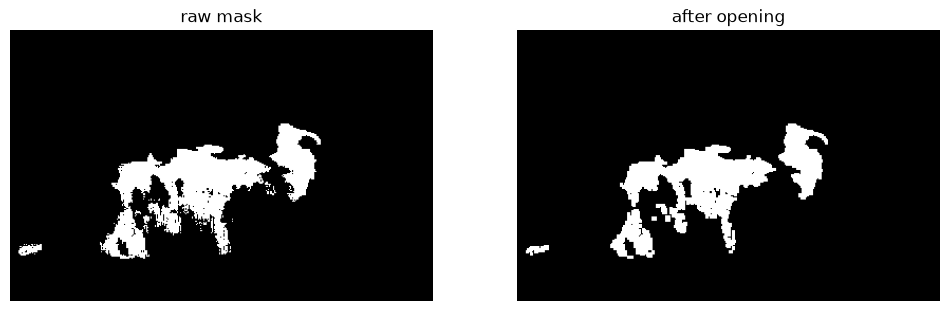

In [3]:
# opening (erode + dilate) removes small noise
open_kernel = np.ones((OPEN_KERNEL, OPEN_KERNEL), np.uint8)
clean_mask = cv2.morphologyEx(raw_mask, cv2.MORPH_OPEN, open_kernel)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].imshow(raw_mask, cmap="gray"); axes[0].set_title("raw mask")
axes[1].imshow(clean_mask, cmap="gray"); axes[1].set_title("after opening")
for ax in axes: ax.axis("off")
plt.show()

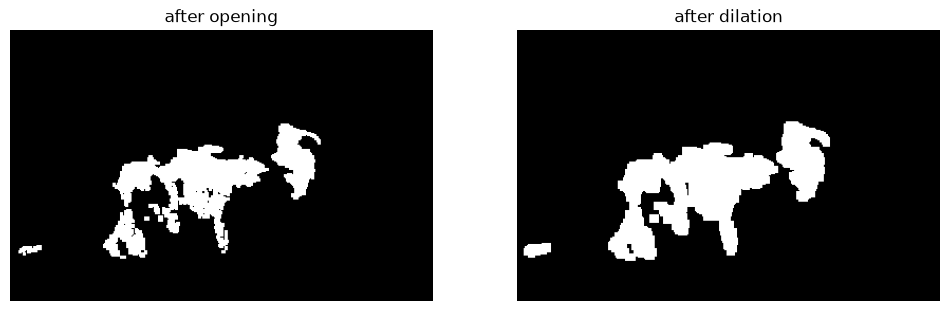

In [4]:
# dilate so pieces of the same fire become one region
dilate_kernel = np.ones((DILATE_KERNEL, DILATE_KERNEL), np.uint8)
fire_mask = cv2.dilate(clean_mask, dilate_kernel)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].imshow(clean_mask, cmap="gray"); axes[0].set_title("after opening")
axes[1].imshow(fire_mask, cmap="gray"); axes[1].set_title("after dilation")
for ax in axes: ax.axis("off")
plt.show()

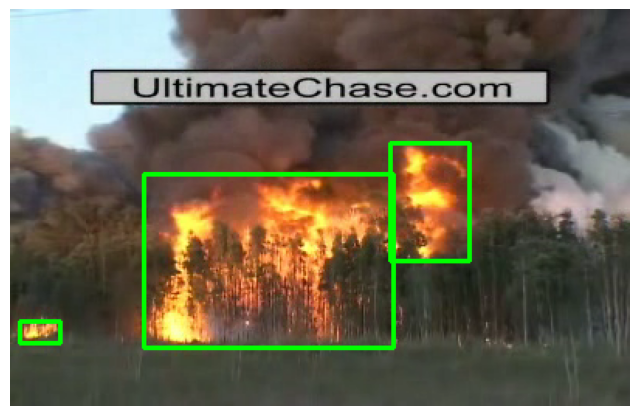

In [5]:
# bounding box around each connected region
contours, _ = cv2.findContours(fire_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
result = image.copy()
for contour in contours:
    x, y, w, h = cv2.boundingRect(contour)
    cv2.rectangle(result, (x, y), (x + w, y + h), (0, 255, 0), 2)

plt.figure(figsize=(8, 6))
plt.imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB)); plt.axis("off")
plt.show()

cv2.imwrite("fire_boxes.png", result);